# Una esfera en un plano

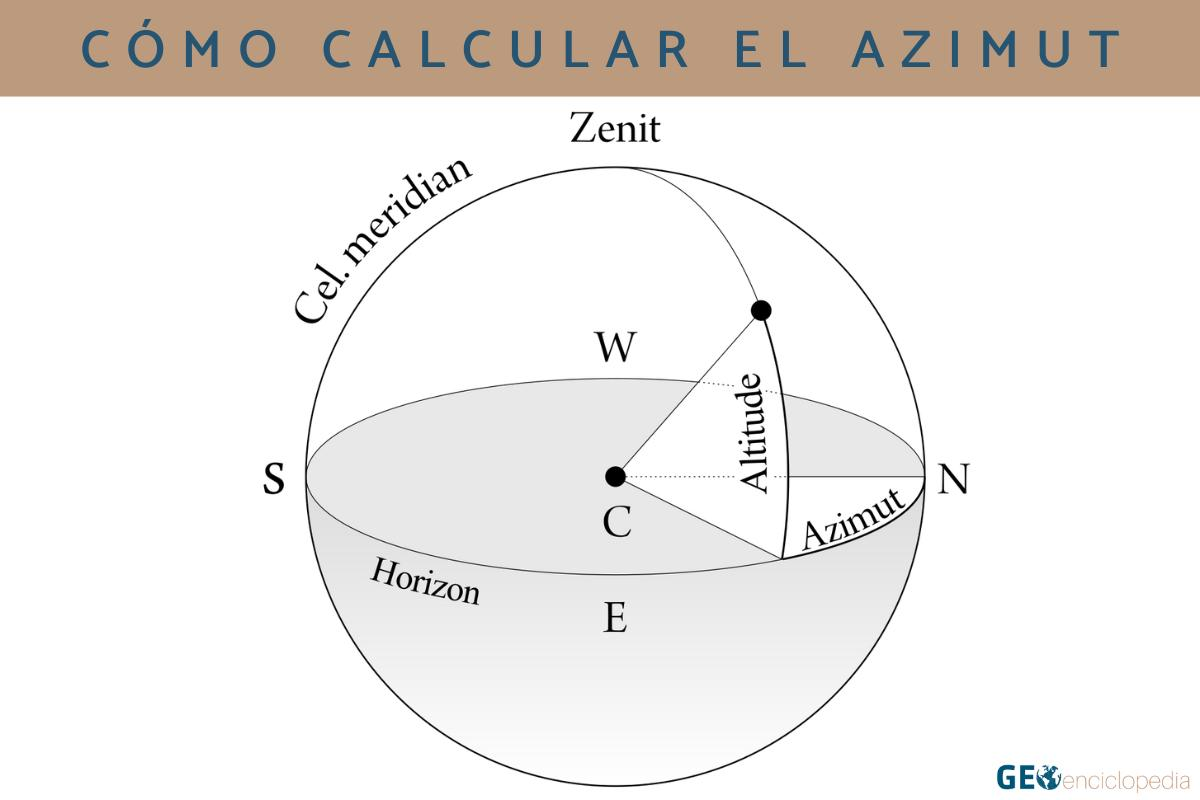

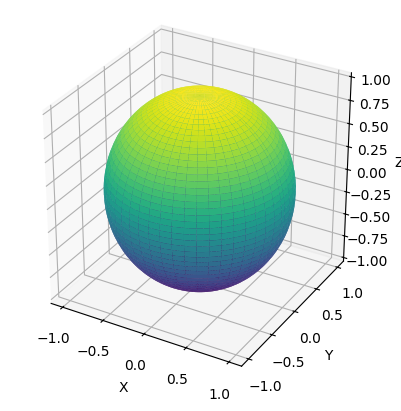

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la esfera
r = 1
#np.pi = π -> Y hacemos una lista de 0 a 2π, osea una vuelta completa
u = np.linspace(0, 2 * np.pi, 100)  # ángulo azimutal
v = np.linspace(0, np.pi, 100)      # ángulo polar

#Convertimos los angulos u y z en coordenadas x,y,z usando trigonometria
# np.outer(a, b) multiplica cada elemento de a con cada elemento de b y arma una tabla, como una tabla de multiplicar.
x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))



fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis') #Hace la superficie usando matrices


# Relacion de aspecto
ax.set_box_aspect((1, 1, 1))  

#Grilla
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.show()


# Sacamos el plano porque se ve feo

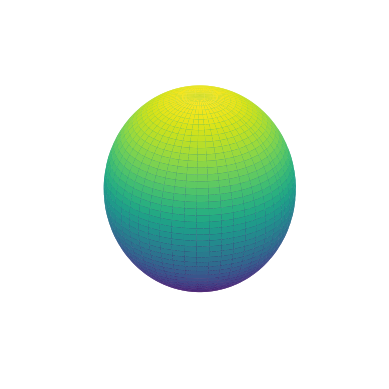

In [2]:


r = 10
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)

x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis')

ax.set_box_aspect((1, 1, 1))
ax.set_axis_off()  # quita grilla, ejes, paneles y etiquetas
plt.show()

# Probamos distintos colores


In [3]:
ax.plot_surface(x, y, z, cmap='plasma')   
ax.plot_surface(x, y, z, cmap='ocean')    
ax.plot_surface(x, y, z, cmap='coolwarm') 
ax.plot_surface(x, y, z, cmap='viridis')

# Agregamos una elipse que en el futuro seria una orbita de satelite

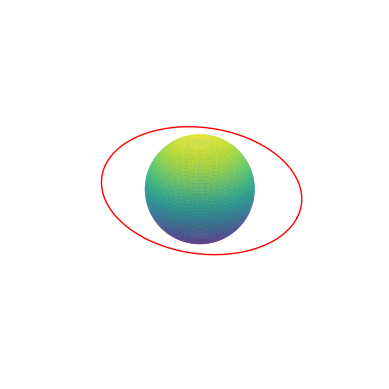

In [4]:


# Esfera
r = 1
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)
x = r * np.outer(np.cos(u), np.sin(v))
y = r * np.outer(np.sin(u), np.sin(v))
z = r * np.outer(np.ones_like(u), np.cos(v))

# Elipse
resolucion_elipse = 300
a, b = 2.0, 1.3          # semiejes mayor y menor
t = np.linspace(0, 2 * np.pi, resolucion_elipse)
ex = a * np.cos(t)
ey = b * np.sin(t)
ez = np.zeros_like(t) #como np.zeros(300)

# Inclinación de la elipse (rotación alrededor del eje X)
theta = np.radians(30)
ey_rot = ey * np.cos(theta) - ez * np.sin(theta)
ez_rot = ey * np.sin(theta) + ez * np.cos(theta)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ex, ey_rot, ez_rot, color='red', linewidth=1)

ax.set_box_aspect((1, 1, 1))

# Encuadre de la "camara"
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)


ax.set_axis_off()
plt.show()

# Le agregamos una esfera en la elipse, lo que vendria siendo un satelite 

In [5]:


def esfera(cx, cy, cz, r, n=60):
    u = np.linspace(0, 2 * np.pi, n)
    v = np.linspace(0, np.pi, n)
    x = cx + r * np.outer(np.cos(u), np.sin(v))
    y = cy + r * np.outer(np.sin(u), np.sin(v))
    z = cz + r * np.outer(np.ones_like(u), np.cos(v))
    return x, y, z


#cx, cy, cz: las coordenadas del centro de la esfera.
#r: el radio.
#n=60: cuántos puntos usar en cada ángulo, que tan suave se ve.

In [6]:
# Elipse (órbita)
a, b = 2.0, 1.3
θ = np.radians(30)

def punto_orbita(t):
    ex = a * np.cos(t)
    ey = b * np.sin(t)
    ez = 0 * t
    # rotación alrededor del eje X
    ey_rot = ey * np.cos(θ) - ez * np.sin(θ)
    ez_rot = ey * np.sin(θ) + ez * np.cos(θ)
    return ex, ey_rot, ez_rot



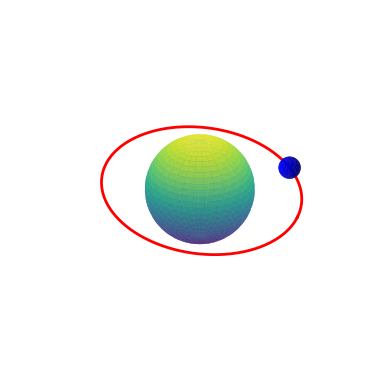

In [7]:

t = np.linspace(0, 2 * np.pi, 300)
ox, oy, oz = punto_orbita(t) # t es una lista: toda la órbita

# Posición de la pelotita sobre la órbita
t0 = np.radians(45)
px, py, pz = punto_orbita(t0)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Esfera grande (central)
x, y, z = esfera(0, 0, 0, 1)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)

# Órbita
ax.plot(ox, oy, oz, color='red', linewidth=2)

# Pelotita orbitando
x2, y2, z2 = esfera(px, py, pz, 0.2)
ax.plot_surface(x2, y2, z2, color='blue')

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
plt.show()

# Lo animamos para ver como quedaria

In [8]:
#Dibuja el satélite en la posición de la órbita que le indiques 
# con t0, y antes borra el que dibujó la vez anterior. 
# La animación se arma llamándola muchas veces con valores de t0 distintos.

def dibujar_pelota(t0):
    if pelota[0] is not None:
        pelota[0].remove()
    px, py, pz = punto_orbita(t0)
    x2, y2, z2 = esfera(px, py, pz, 0.2)
    pelota[0] = ax.plot_surface(x2, y2, z2, color='green')


#Cada vez que se llama a dibujar_pelota(t0):

#borra la pelota vieja
#calcula la posición nueva
#dibuja la pelota en esa posición
#se acuerda de ella para borrarla después    

In [9]:
#convierte el número de cuadro en un ángulo y se lo pasa a dibujar_pelota.
def actualizar(frame):
    dibujar_pelota(2 * np.pi * frame / 120)

In [ ]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

# Elementos fijos
x, y, z = esfera(0, 0, 0, 1, n=60)
ax.plot_surface(x, y, z, cmap='viridis', alpha=0.8)
ax.plot(ox, oy, oz, color='red', linewidth=2)



#--------------------------------
ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-2, 2)
ax.set_ylim(-2, 2)
ax.set_zlim(-2, 2)
ax.set_axis_off()
#--------------------------------



# Pelotita: se dibuja desde el principio
pelota = [None]
#Es una lista con un solo elemento, que al principio es None (nada).
#  Ahí se guarda la esfera naranja que está dibujada en ese momento. 
# Usás una lista, y no una variable suelta, por una cuestión de Python: 
# dentro de una función no podés reasignar una variable de afuera (sin global),
#  pero sí podés modificar el contenido de una lista. Es un truco común.



dibujar_pelota(0)   # posición inicial, así se ve aunque no corra la animación



ani = FuncAnimation(fig, actualizar, frames=120, interval=30, blit=False)

# Blitting es una técnica de optimización para animaciones:
#  en vez de redibujar la figura completa en cada cuadro, 
# matplotlib redibuja solo lo que cambió y deja el resto como estaba



plt.close() # Sin esta linea se generan 2 "imagenes", una foto estatica y la animacion
HTML(ani.to_jshtml())


# Convierte la animación en un bloque de HTML con JavaScript. Para eso matplotlib:

#Ejecuta tu función actualizar para cada uno de los 120 cuadros.
#Guarda cada cuadro como una imagen.
#Mete todas las imágenes dentro de una página HTML, junto con un pequeño reproductor en JavaScript.



# Pasamos de datos inventados a datos reales de un satélite

In [1]:
# A partir de acá usamos las funciones del módulo Funciones3D.py
# (tiene que estar en la misma carpeta que este notebook).
# Lo importamos como f3d para no pisar las funciones que definimos más arriba
# (esfera, punto_orbita, dibujar_pelota y actualizar), porque las del módulo
# reciben los parámetros (ax, a, b, theta) en vez de leerlos de variables globales.
import Funciones3D as f3d

RUTA_JSON = "datos/satelites.json"
INDICE = 0   # posición del satélite dentro de la lista

# leer_satelites abre el JSON y devuelve la lista de satélites (cada uno es un diccionario)
registros = f3d.leer_satelites(RUTA_JSON)

if not registros:   # solo para poder probar sin el JSON (ISS de ejemplo)
    registros = [{
        "OBJECT_NAME": "ISS (ZARYA)", "MEAN_MOTION": 15.5, "ECCENTRICITY": 0.0005,
        "INCLINATION": 51.6, "RA_OF_ASC_NODE": 100.0, "ARG_OF_PERICENTER": 80.0,
        "MEAN_ANOMALY": 10.0,
    }]

# inspeccionar_satelite saca los campos vacíos y completa con 0 los parámetros
# orbitales que falten (y deja un aviso en 'aviso_grafico')
satelite = f3d.inspeccionar_satelite(registros[INDICE])
satelite

ModuleNotFoundError: No module named 'matplotlib'

# Calculamos la física de la órbita

In [ ]:
# Semieje mayor (sale de MEAN_MOTION con la 3ª ley de Kepler), radios y alturas
# de perigeo (punto más cercano a la Tierra) y apogeo (el más lejano). Todo en km.
fisica = f3d.calcular_parametros_fisicos(satelite)

if not fisica:
    raise ValueError("No se pudieron calcular los parámetros físicos de este satélite.")

# Nuestra esfera mide 1, así que pasamos todo a "radios terrestres"
# (dividimos por el radio de la Tierra, 6378 km).
# orbita_valida avisa si el perigeo queda adentro de la Tierra.
norm = f3d.normalizar_parametros(fisica)

print("En km:", fisica)
print("En radios terrestres:", norm)

# Velocidad y tiempo

In [ ]:
DURACION_VUELTA_S = 10   # cuánto va a durar una vuelta orbital en la animación

# Una órbita real tarda horas (la ISS ~93 min), así que hay que acelerarla.
# Primera llamada: solo para conocer el período real.
cinematica = f3d.velocidad_y_tiempo(satelite, fisica)

# factor de aceleración = período real / duración que queremos en pantalla
factor = cinematica["periodo_s"] / DURACION_VUELTA_S

# Segunda llamada: ya con el factor
cinematica = f3d.velocidad_y_tiempo(satelite, fisica, factor_aceleracion=factor)

print(f"Período: {cinematica['periodo_min']:.1f} min")
print(f"Velocidad en el perigeo: {cinematica['v_perigeo_kms']:.2f} km/s")
print(f"Velocidad en el apogeo:  {cinematica['v_apogeo_kms']:.2f} km/s")
print(f"1 vuelta = {DURACION_VUELTA_S} s en pantalla (x{factor:,.0f})")

# La elipse ahora sale de los datos del satélite

In [ ]:
# Mismos pasos que antes, pero a, b y la inclinación ya no los inventamos: salen del JSON.
e = satelite.get("ECCENTRICITY", 0.0)    # excentricidad: 0 = círculo, cerca de 1 = elipse muy alargada

a_sat = norm["a_norm"]                   # semieje mayor, en radios terrestres
b_sat = a_sat * np.sqrt(1 - e ** 2)      # semieje menor
inc = np.radians(satelite.get("INCLINATION", 0.0))   # inclinación, en radianes

t = np.linspace(0, 2 * np.pi, 300)
orb_x, orb_y, orb_z = f3d.punto_orbita(t, a_sat, b_sat, inc)   # t es una lista: toda la órbita

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')

x, y, z = f3d.esfera(0, 0, 0, 1, n=60)
ax.plot_surface(x, y, z, color='lightsteelblue', alpha=0.3)
ax.plot(orb_x, orb_y, orb_z, color='red', linewidth=2)

# Encuadre: antes era fijo (-2, 2). Ahora depende del tamaño de la órbita
# (con 1.9 como mínimo, para que después entren los ejes)
lim = max(a_sat * 1.1, 1.9)
ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_zlim(-lim, lim)
ax.set_axis_off()
plt.show()

# Le agregamos la malla a la Tierra y los ejes para tener referencias

In [ ]:

fig = plt.figure(figsize=(8, 8))

# Agrega un sistema de coordenadas tridimensional (ejes X, Y, Z) a la figura
ax = fig.add_subplot(projection='3d')

# Llama a la función 'esfera' para generar la malla matemática 3D de la Tierra
# (centrada en 0,0,0, con radio 1 y resolución 'n=60'), devolviendo listas de puntos x, y, z
x, y, z = f3d.esfera(0, 0, 0, 1, n=60)

#Dibuja la superficie 3D de la Tierra usando los puntos anteriores;
# se pinta de azul acero claro ('lightsteelblue') y con un 30% de opacidad ('alpha=0.3')
ax.plot_surface(x, y, z, color='lightsteelblue', alpha=0.3)

# Itera sobre cada elemento devuelto por 'lineas_tierra()' (que contiene los meridianos y paralelos)
# Cada elemento trae empaquetados los puntos, el color asignado y el grosor de línea
for pts, color, ancho in f3d.lineas_tierra():
    
    # Desempaqueta (*pts) la matriz de coordenadas (x, y, z) para que Matplotlib 
    # pueda dibujarlas aplicando el color y el grosor ('lw') correspondientes
    ax.plot(*pts, color=color, lw=ancho)

# Llama a la función externa para dibujar el eje polar (Norte-Sur) de color negro 
# y las flechas tridimensionales de referencia para los ejes X, Y y Z con sus etiquetas
f3d.dibujar_ejes(ax)

# Dibuja la trayectoria orbital del satélite en el espacio 3D 
# usando las listas de coordenadas (orb_x, orb_y, orb_z) con color rojo y grosor de línea 2
ax.plot(orb_x, orb_y, orb_z, color='red', linewidth=2)

# Configura la proporción geométrica de la gráfica en una escala equitativa (1:1:1) 
# para evitar que la esfera o las órbitas se deformen visualmente
ax.set_box_aspect((1, 1, 1))

# Define los límites de visualización mínimos y máximos para el eje X basados en la variable 'lim'
ax.set_xlim(-lim, lim)

# Define los límites de visualización mínimos y máximos para el eje Y basados en la variable 'lim'
ax.set_ylim(-lim, lim)

# Define los límites de visualización mínimos y máximos para el eje Z basados en la variable 'lim'
ax.set_zlim(-lim, lim)

# Oculta las marcas, números y líneas de los ejes cartesianos predeterminados para dejar el gráfico limpio
ax.set_axis_off()

# Renderiza y abre la ventana interactiva para mostrar el gráfico 3D completo en pantalla
plt.show()

# Animamos el satélite con los datos reales

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')

# Elementos fijos
x, y, z = f3d.esfera(0, 0, 0, 1, n=60)
ax.plot_surface(x, y, z, color='lightsteelblue', alpha=0.3)

for pts, color, ancho in f3d.lineas_tierra():
    ax.plot(*pts, color=color, lw=ancho)

f3d.dibujar_ejes(ax)
ax.plot(orb_x, orb_y, orb_z, color='red', linewidth=2)

ax.set_box_aspect((1, 1, 1))
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_zlim(-lim, lim)
ax.set_axis_off()

# Datos del satélite (los calculamos arriba con velocidad_y_tiempo)
ax.text2D(0.02, 0.97,
          f"{satelite.get('OBJECT_NAME')}\n"
          f"Periodo: {cinematica['periodo_min']:.1f} min\n"
          f"Velocidad en el perigeo: {cinematica['v_perigeo_kms']:.2f} km/s\n"
          f"Velocidad en el apogeo:  {cinematica['v_apogeo_kms']:.2f} km/s\n"
          f"1 vuelta = {DURACION_VUELTA_S} s en pantalla (x{factor:,.0f})\n"
          f"{satelite['aviso_grafico']}",
          transform=ax.transAxes, va='top', family='monospace', fontsize=9)

# Pelotita: se dibuja desde el principio.
# Las funciones del módulo reciben ax, a, b y theta como parámetros.
pelota_sat = [None]
f3d.dibujar_pelota(0, pelota_sat, ax, a_sat, b_sat, inc)   # posición inicial

# actualizar usa 120 cuadros por vuelta, así que el intervalo entre cuadros
# sale de dividir la duración de la vuelta en 120
intervalo = DURACION_VUELTA_S * 1000 / 120

# fargs: los argumentos extra que FuncAnimation le pasa a actualizar después de 'frame'
ani = FuncAnimation(fig, f3d.actualizar, frames=120, interval=intervalo, blit=False,
                    fargs=(pelota_sat, ax, a_sat, b_sat, inc))

plt.close()   # sin esta línea se generan 2 "imágenes": una foto estática y la animación
HTML(ani.to_jshtml())

# Lo que todavía no tenemos

- **La Tierra no gira.** `rotar_z` ya existe en el módulo, pero hay que usarla en cada cuadro de la animación.
- **La velocidad no se nota en el movimiento.** El satélite avanza siempre al mismo ritmo; la velocidad real (más rápida en el perigeo, más lenta en el apogeo) por ahora solo aparece como dato en pantalla.
- **La Tierra está en el centro de la elipse**, no en un foco como en una órbita real. Con órbitas muy excéntricas se nota.
- **Solo usamos la inclinación.** `RA_OF_ASC_NODE` y `ARG_OF_PERICENTER` están en los datos pero todavía no se aplican a la órbita.
- **El tamaño del satélite es fijo** (radio 0.2), y en órbitas bajas como la de la ISS se ve más grande de lo que debería.